
## Trabalho Final - Machine Learning ##

* integrante 1
* integrante 2
* integrante 3 -> Paulo Santana SilvA RA:376322
* integrante 4

Neste trabalho, como parte do time de analistas da Quantum Finance, vocês deverão explorar uma base de dados originalmente utilizada para classificação de score de crédito, disponível no Kaggle (https://www.kaggle.com/datasets/parisrohan/credit-score-classification), utilizando técnicas de Análise Exploratória de Dados (EDA) e algoritmos de Machine Learning supervisionados.

O objetivo é aplicar e interpretar os resultados obtidos, assim como criar um sistema que gere valor a partir da análise da base de dados.

Modelo de Classificação Supervisionada

Desenvolver um modelo de classificação supervisionada para prever a classificação de crédito dos indivíduos presentes na base.

Passos esperados:
* Realizar uma análise exploratória dos dados (EDA) para entender as características principais da base e as relações entre variáveis; 2 pontos

* Implementar um pipeline de modelo de classificação usando Random Forest, XGBoost e LightGBM. Use GridSearch para otimizar os parametros de cada modelo; 4 pontos

* Avaliar os resultados utilizando a métrica mais adequada e justifique sua escolha; 2 pontos

* Apresentar os resultados, indicando a métrica no conjunto de treino (train.csv) e explicar como o modelo pode ser utilizado para decisões financeiras. 2 pontos

Entregáveis:

    Este jupyter notebook compactado (.zip) executado e com os resultados aparentes (não serão aceitos outros formatos)
    Grupo com mínimo de 2 pessoas e, idealmente, 4.



### Importação de Bibliotecas ##

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)


In [2]:
headers = [
"ID_CLIENTE",
"TIPO_FUNCIONARIO",
"DIA_PAGAMENTO",
"TIPO_ENVIO_APLICACAO",
"QUANT_CARTOES_ADICIONAIS",
"TIPO_ENDERECO_POSTAL",
"SEXO",
"ESTADO_CIVIL",
"QUANT_DEPENDENTES",
"NIVEL_EDUCACIONAL",
"ESTADO_NASCIMENTO",
"CIDADE_NASCIMENTO",
"NACIONALIDADE",
"ESTADO_RESIDENCIAL",
"CIDADE_RESIDENCIAL",
"BAIRRO_RESIDENCIAL",
"FLAG_TELEFONE_RESIDENCIAL",
"CODIGO_AREA_TELEFONE_RESIDENCIAL",
"TIPO_RESIDENCIA",
"MESES_RESIDENCIA",
"FLAG_TELEFONE_MOVEL",
"FLAG_EMAIL",
"RENDA_PESSOAL_MENSAL",
"OUTRAS_RENDAS",
"FLAG_VISA",
"FLAG_MASTERCARD",
"FLAG_DINERS",
"FLAG_AMERICAN_EXPRESS",
"FLAG_OUTROS_CARTOES",
"QUANT_CONTAS_BANCARIAS",
"QUANT_CONTAS_BANCARIAS_ESPECIAIS",
"VALOR_PATRIMONIO_PESSOAL",
"QUANT_CARROS",
"EMPRESA",
"ESTADO_PROFISSIONAL",
"CIDADE_PROFISSIONAL",
"BAIRRO_PROFISSIONAL",
"FLAG_TELEFONE_PROFISSIONAL",
"CODIGO_AREA_TELEFONE_PROFISSIONAL",
"MESES_NO_TRABALHO",
"CODIGO_PROFISSAO",
"TIPO_OCUPACAO",
"CODIGO_PROFISSAO_CONJUGE",
"NIVEL_EDUCACIONAL_CONJUGE",
"FLAG_DOCUMENTO_RESIDENCIAL",
"FLAG_RG",
"FLAG_CPF",
"FLAG_COMPROVANTE_RENDA",
"PRODUTO",
"FLAG_REGISTRO_ACSP",
"IDADE",
"CEP_RESIDENCIAL_3",
"CEP_PROFISSIONAL_3",
"ROTULO_ALVO_MAU"
]

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/master/dados/credit.csv", encoding='unicode_escape', sep='\t', names=headers)
df.head()

/tmp/ipykernel_9011/2863976107.py:1: DtypeWarning: Columns (51: CEP_RESIDENCIAL_3, 52: CEP_PROFISSIONAL_3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/master/dados/credit.csv", encoding='unicode_escape', sep='\t', names=headers)


,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,NIVEL_EDUCACIONAL,...,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU
0,1,C,5,Web,0,1,F,6,1,0,...,0,0,0,0,1,N,32,595,595,1
1,2,C,15,Carga,0,1,F,2,0,0,...,0,0,0,0,1,N,34,230,230,1
2,3,C,5,Web,0,1,F,2,0,0,...,0,0,0,0,1,N,27,591,591,0
3,4,C,20,Web,0,1,F,2,0,0,...,0,0,0,0,1,N,61,545,545,0
4,5,C,10,Web,0,1,M,2,0,0,...,0,0,0,0,1,N,48,235,235,1


In [4]:

# Inspeção básica
print(df.shape)  # Linhas e colunas
print(df.info())  # Tipos de dados e valores nulos
print(df.describe())  # Estatísticas descritivas (média, desvio padrão, min, max)


(50000, 54)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 54 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID_CLIENTE                         50000 non-null  int64  
 1   TIPO_FUNCIONARIO                   50000 non-null  str    
 2   DIA_PAGAMENTO                      50000 non-null  int64  
 3   TIPO_ENVIO_APLICACAO               50000 non-null  str    
 4   QUANT_CARTOES_ADICIONAIS           50000 non-null  int64  
 5   TIPO_ENDERECO_POSTAL               50000 non-null  int64  
 6   SEXO                               50000 non-null  str    
 7   ESTADO_CIVIL                       50000 non-null  int64  
 8   QUANT_DEPENDENTES                  50000 non-null  int64  
 9   NIVEL_EDUCACIONAL                  50000 non-null  int64  
 10  ESTADO_NASCIMENTO                  50000 non-null  str    
 11  CIDADE_NASCIMENTO                  50000 non-null  st

### Percenrtual de Missing###

In [5]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

print(missing[missing > 0])



BAIRRO_PROFISSIONAL          67.566
CIDADE_PROFISSIONAL          67.566
NIVEL_EDUCACIONAL_CONJUGE    64.676
CODIGO_PROFISSAO_CONJUGE     57.768
CODIGO_PROFISSAO             15.512
TIPO_OCUPACAO                14.626
MESES_RESIDENCIA              7.554
TIPO_RESIDENCIA               2.698
dtype: float64


Investigando se o missing carregada alguma informação correlacionada a variavel alvo:


In [6]:
for col in [
    'TIPO_RESIDENCIA',
    'MESES_RESIDENCIA',
    'CODIGO_PROFISSAO'
]:
    
    temp = df[col].isna().astype(int)

    print(
        pd.DataFrame({
            'count': temp.groupby(temp).size(),
            'mau_rate': df.groupby(temp)['ROTULO_ALVO_MAU'].mean()
        })
    )

                 count  mau_rate
TIPO_RESIDENCIA                 
0                48651  0.261146
1                 1349  0.249073
                  count  mau_rate
MESES_RESIDENCIA                 
0                 46223  0.261818
1                  3777  0.248610
                  count  mau_rate
CODIGO_PROFISSAO                 
0                 42244  0.260652
1                  7756  0.261733


## Análise da variavel Alvo ##
### Distribuição ###


In [7]:
df['ROTULO_ALVO_MAU'].value_counts(normalize=True)

ROTULO_ALVO_MAU
0    0.73918
1    0.26082
Name: proportion, dtype: float64

<Axes: xlabel='ROTULO_ALVO_MAU', ylabel='count'>

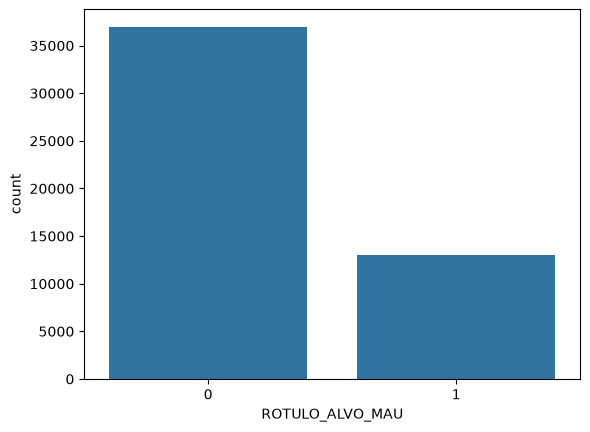

In [8]:
#Grafico
sns.countplot(
    data=df,
    x='ROTULO_ALVO_MAU'
)

75% bom pagador e 25% Mau pagador

### Perfil dos Númericos ###


In [9]:
numericas = [
'IDADE',
'DIA_PAGAMENTO',
'QUANT_DEPENDENTES',
'QUANT_CARTOES_ADICIONAIS',
'RENDA_PESSOAL_MENSAL',
'OUTRAS_RENDAS',
'VALOR_PATRIMONIO_PESSOAL',
'QUANT_CARROS',
'MESES_NO_TRABALHO',
'MESES_RESIDENCIA',
'QUANT_CONTAS_BANCARIAS'
]

In [10]:
#Estatistica descritiva
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
IDADE,50000.0,43.248520,14.989050,6.0,31.0,41.0,53.0,106.0
DIA_PAGAMENTO,50000.0,12.869920,6.608385,1.0,10.0,10.0,15.0,25.0
QUANT_DEPENDENTES,50000.0,0.650520,1.193655,0.0,0.0,0.0,1.0,53.0
QUANT_CARTOES_ADICIONAIS,50000.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
RENDA_PESSOAL_MENSAL,50000.0,886.678437,7846.959327,60.0,360.0,500.0,800.0,959000.0
OUTRAS_RENDAS,50000.0,35.434760,891.515142,0.0,0.0,0.0,0.0,194344.0
VALOR_PATRIMONIO_PESSOAL,50000.0,2322.372380,42357.984397,0.0,0.0,0.0,0.0,6000000.0
QUANT_CARROS,50000.0,0.336140,0.472392,0.0,0.0,0.0,1.0,1.0
MESES_NO_TRABALHO,50000.0,0.009320,0.383453,0.0,0.0,0.0,0.0,35.0
MESES_RESIDENCIA,46223.0,9.727149,10.668841,0.0,1.0,6.0,15.0,228.0


In [11]:
#olhar valores do campos principalmente campos com limites inteiros

for coluna in numericas:
  print(f'Campo: {coluna}')
  print(df[coluna].unique())
  print('-' * 40)


Campo: IDADE
[ 32  34  27  61  48  40  28  31  41  36  29  19  49  58  69  39  42  47
  30  26  60  45  56  71  38  53  79  22  37  55  25  67  21  50  51  84
  43  44  57  33  20  63  62  24  54  64  92  65  73  91  35  76  80  59
  46  70  66  52  23  77  68  18  74  72  75  78  83  81  98  97  85  90
  87  82  17  86  94  89  88  96 106  95  99 101  93   6 100   7  14]
----------------------------------------
Campo: DIA_PAGAMENTO
[ 5 15 20 10 25  1]
----------------------------------------
Campo: QUANT_DEPENDENTES
[ 1  0  2  3  4  5  6  7 10  8 13 11  9 12 14 15 53]
----------------------------------------
Campo: QUANT_CARTOES_ADICIONAIS
[0]
----------------------------------------
Campo: RENDA_PESSOAL_MENSAL
[ 900.    750.    500.   ...  234.25 1443.27  719.38]
----------------------------------------
Campo: OUTRAS_RENDAS
[0.00000e+00 1.34000e+02 6.11000e+02 1.45000e+03 3.20000e+02 1.00000e+03
 7.06000e+02 2.50000e+02 3.50000e+02 1.40000e+03 8.00000e+02 7.00000e+02
 9.50000e+01 2.4

### Analisando Outliers ###

<Axes: xlabel='RENDA_PESSOAL_MENSAL'>

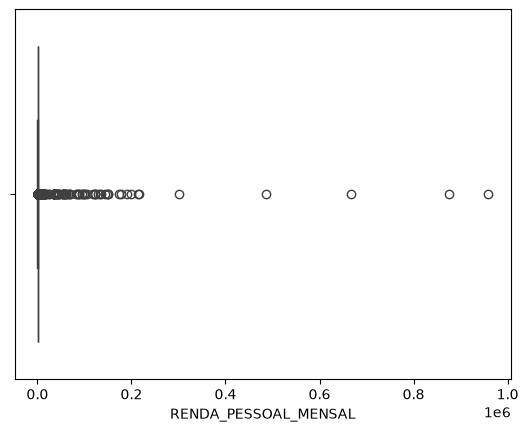

In [12]:
#baseado na analise anterior os campos que saltam a vistas na questão de outliers sao RENDA_PESSOAL_MENSAL e VALOR_PATRIMONIO_PESSOAL
sns.boxplot(
    x=df['RENDA_PESSOAL_MENSAL']
)

In [13]:
df['RENDA_PESSOAL_MENSAL'].quantile(
    [0.90,0.95,0.99,0.995]
)

0.900    1315.1000
0.950    1802.0500
0.990    3678.2187
0.995    5187.9406
Name: RENDA_PESSOAL_MENSAL, dtype: float64

<Axes: xlabel='VALOR_PATRIMONIO_PESSOAL'>

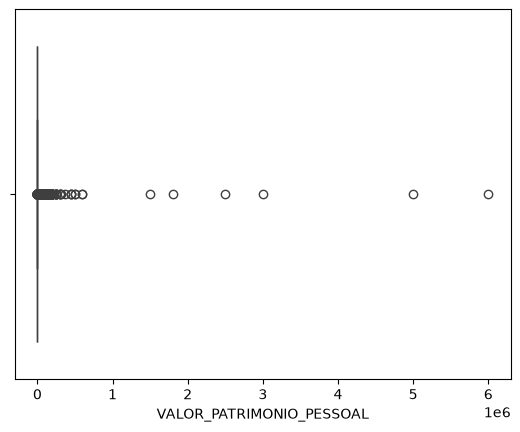

In [14]:
sns.boxplot(
    x=df['VALOR_PATRIMONIO_PESSOAL']
)

Os campos flag estão com dominio [0,1]. O campo QUANT_DEPENDENTES possui outliers (ex: 53 dependentes estranho). Sobre o campo ESTADO_CIVIL não temos o que representa cada item do dominio. Alguns campos apresentam valores NAN mas como iremos utilizar algoritmos como XGBoost e LightGBM estes possuem mecanismos internos para lidar com NaNs automaticamente durante o treinamento, eliminando a necessidade de imputação manual

### Correlação com alvo ### 

In [15]:
corr = df.select_dtypes(
    include=['int64','float64']
).corr()['ROTULO_ALVO_MAU']

corr.sort_values()

IDADE                              -0.107886
CODIGO_PROFISSAO_CONJUGE           -0.034505
NIVEL_EDUCACIONAL_CONJUGE          -0.032215
ESTADO_CIVIL                       -0.030380
MESES_RESIDENCIA                   -0.029336
FLAG_MASTERCARD                    -0.017658
CODIGO_PROFISSAO                   -0.011593
FLAG_EMAIL                         -0.008067
MESES_NO_TRABALHO                  -0.007073
FLAG_VISA                          -0.005398
VALOR_PATRIMONIO_PESSOAL           -0.003886
TIPO_ENDERECO_POSTAL               -0.002423
NACIONALIDADE                      -0.000952
FLAG_AMERICAN_EXPRESS               0.000337
FLAG_OUTROS_CARTOES                 0.001410
FLAG_DINERS                         0.002240
RENDA_PESSOAL_MENSAL                0.002819
OUTRAS_RENDAS                       0.004442
ID_CLIENTE                          0.010509
QUANT_CARROS                        0.011706
QUANT_CONTAS_BANCARIAS              0.011997
QUANT_CONTAS_BANCARIAS_ESPECIAIS    0.011997
QUANT_DEPE

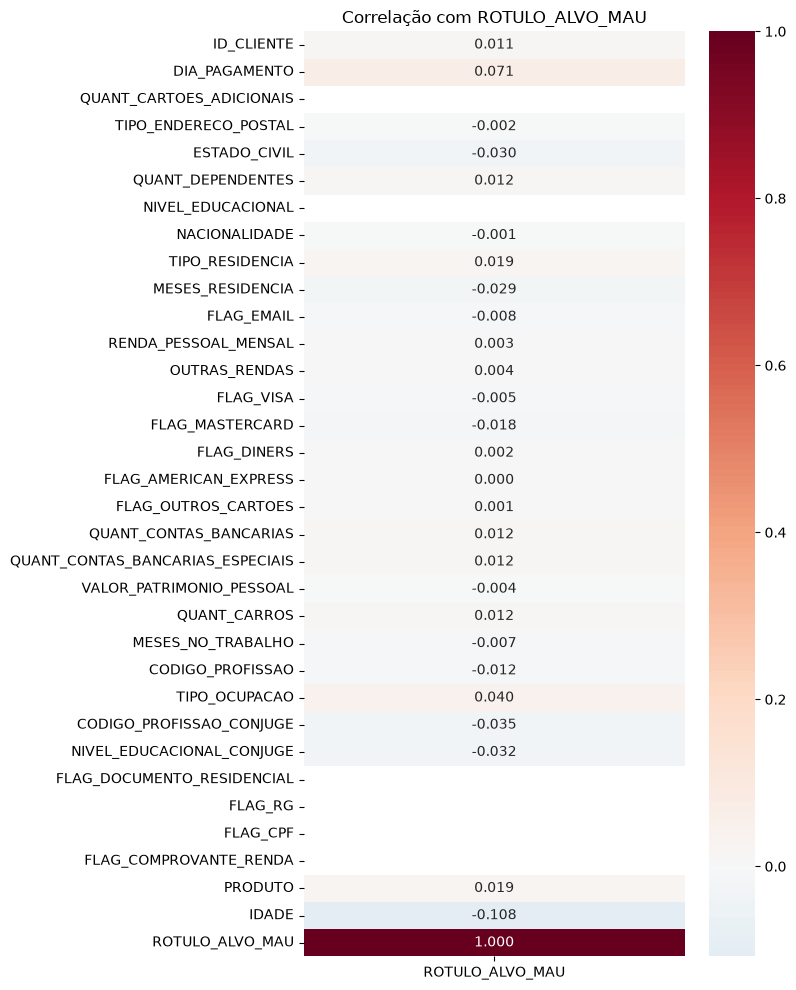

In [16]:
#Plotando o Heatmap
plt.figure(figsize=(8, 10))

corr_target = corr.to_frame()

sns.heatmap(
    corr_target,
    annot=True,
    cmap='RdBu_r',
    center=0,
    fmt='.3f'
)

plt.title('Correlação com ROTULO_ALVO_MAU')
plt.tight_layout()
plt.show()

### Interpretação ##

* Nenhuma variável possui correlação linear forte com o alvo
* As feastures com maior correlação com alvo foram: IDADE, DIA_PAGAMENTO, TIPO_OCUPACAO, CODIGO_PROFISSAO_CONJUGE, NIVEL_EDUCACIONAL_CONJUGE
* A IDADE parece ser a variável numérica mais relevante
* a feature DIA_PAGAMENTO necessita de investigação

<Axes: xlabel='ROTULO_ALVO_MAU', ylabel='IDADE'>

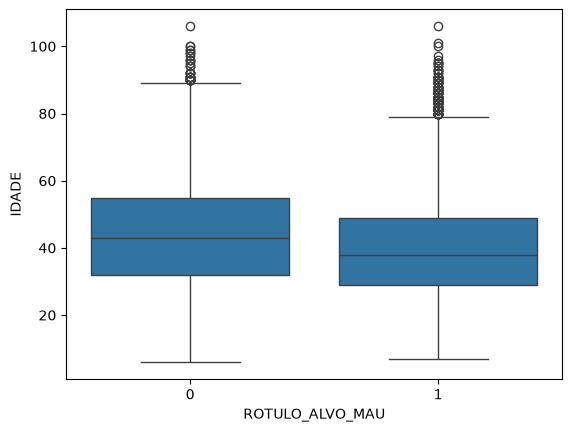

In [17]:
#verrificando se com crescimento da idade diminiu a inamdiplencia
sns.boxplot(
    data=df,
    x='ROTULO_ALVO_MAU',
    y='IDADE'
)

<Axes: xlabel='DIA_PAGAMENTO'>

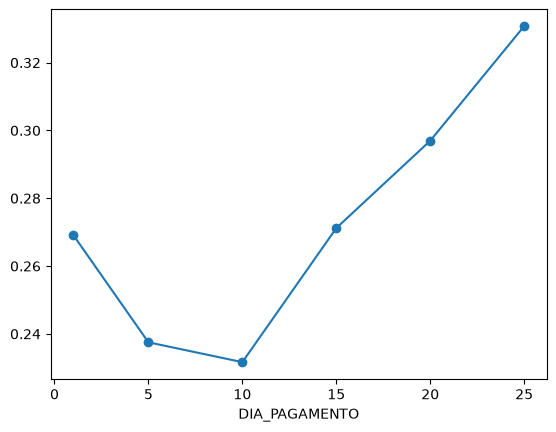

In [18]:
#verificando se inadimplencia varia conforme inicio e o fim do mês
tmp = (
    df.groupby('DIA_PAGAMENTO')
      ['ROTULO_ALVO_MAU']
      .agg(['count','mean'])
)

tmp['mean'].plot(marker='o')

### Análise univariada das categóricas ###

In [19]:
cat_cols = df.select_dtypes(
    include=['object','string']
).columns

In [20]:
for col in cat_cols:
    
    print(f'\n{col}')

    display(
        df.groupby(col)['ROTULO_ALVO_MAU']
          .agg(['count','mean'])
          .sort_values('count', ascending=False)
          .head(20)
    )


TIPO_FUNCIONARIO


,count,mean
TIPO_FUNCIONARIO,,
C,50000,0.26082



TIPO_ENVIO_APLICACAO


,count,mean
TIPO_ENVIO_APLICACAO,,
Web,28206,0.258101
0,19461,0.269102
Carga,2333,0.224604



SEXO


,count,mean
SEXO,,
F,30805,0.252881
M,19130,0.273288
N,48,0.333333
,17,0.411765


... (30 outputs left out)


CEP_RESIDENCIAL_3


,count,mean
CEP_RESIDENCIAL_3,,
960,721,0.138696
591,547,0.294333
570,508,0.311024
628,459,0.222222
456,444,0.265766
960,364,0.173077
689,350,0.254286
596,345,0.246377
685,340,0.261765



CEP_PROFISSIONAL_3


,count,mean
CEP_PROFISSIONAL_3,,
960,721,0.138696
591,547,0.294333
570,508,0.311024
628,459,0.222222
456,444,0.265766
960,364,0.173077
689,350,0.254286
596,345,0.246377
685,340,0.261765


### Resumo ###

**Categóricas binárias**
**features:**
* SEXO
* EMPRESA
* FLAG_* (telefone)

**Categóricas nominais de baixa cardinalidade**

* ESTADO_NASCIMENTO
* ESTADO_RESIDENCIAL
* TIPO_ENVIO_APLICACAO

**Categóricas de alta cardinalidade**

* CIDADE_*
* BAIRRO_*

**Códigos que devem ser tratados como categóricos**

* CEP_*_3
* CODIGO_AREA_TELEFONE_*

**Variáveis constantes (aptas remoção)**

* TIPO_FUNCIONARIO
* FLAG_TELEFONE_MOVEL
* FLAG_REGISTRO_ACSP

#### Variáveis categóricas codificadas ####
*Estas variáveis não são adequadamente analisadas por boxplot (melhor para analisar variaveis contínuas).*
* ESTADO_CIVIL
* NACIONALIDADE
* NIVEL_EDUCACIONAL
* NIVEL_EDUCACIONAL_CONJUGE
* TIPO_ENDERECO_POSTAL
* TIPO_RESIDENCIA
*Melhor visualização dos graficos para estas variaveis foi gerado abaixo

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


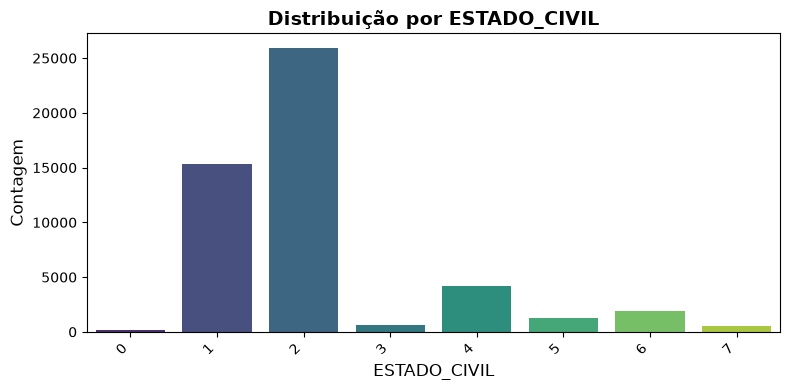

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


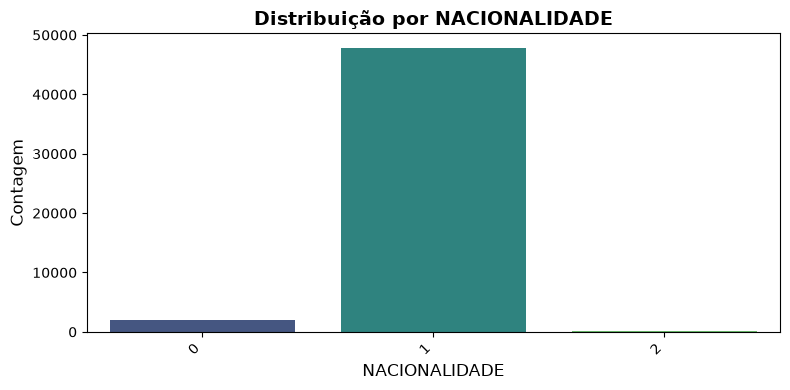

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


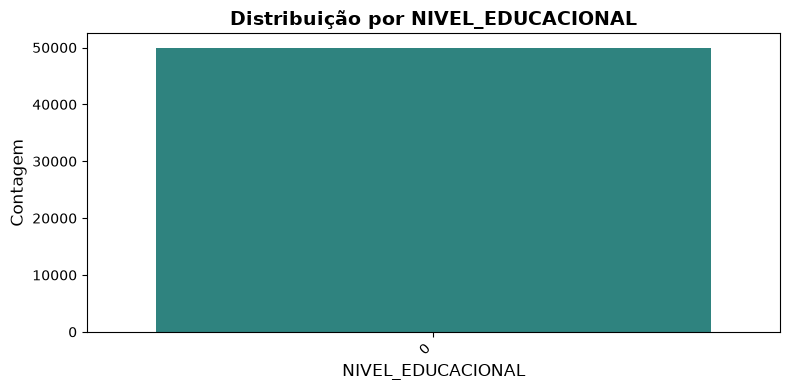

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


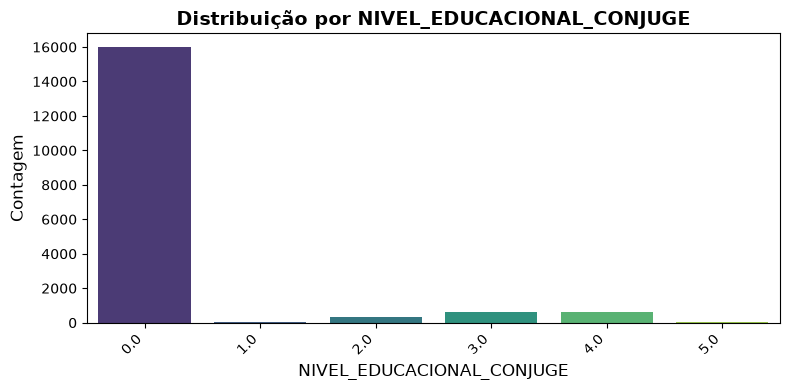

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


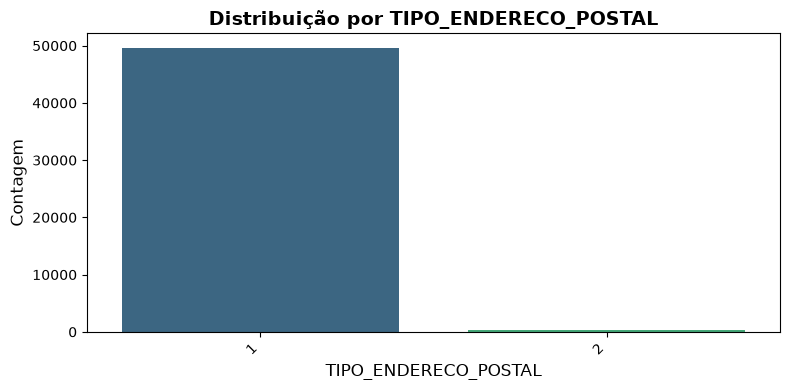

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


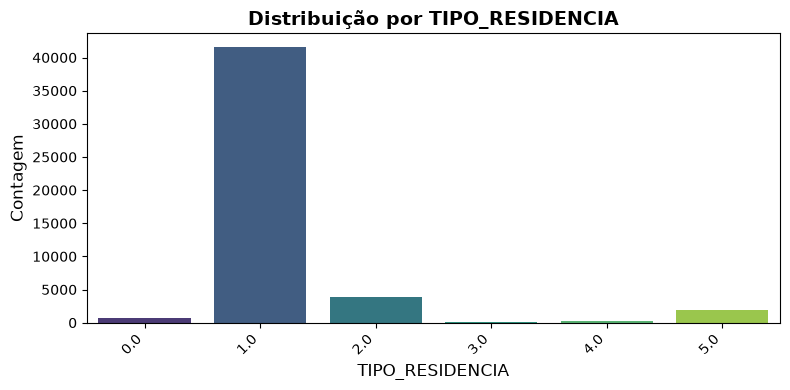

/tmp/ipykernel_9011/4054193569.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=coluna, data=df, palette="viridis")


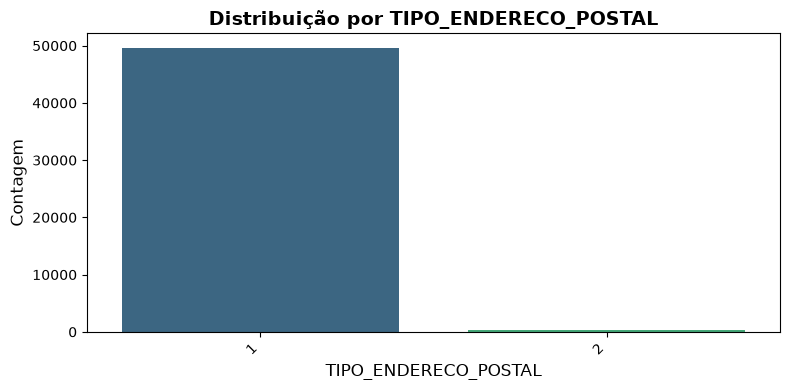

Gráficos gerados com sucesso!


In [21]:
#melhor visualização das Variáveis categóricas codificadas

colunas = [
    "ESTADO_CIVIL",
    "NACIONALIDADE",
    "NIVEL_EDUCACIONAL",
    "NIVEL_EDUCACIONAL_CONJUGE",
    "TIPO_ENDERECO_POSTAL",
    "TIPO_RESIDENCIA",
    "TIPO_ENDERECO_POSTAL"
]

# Loop para gerar e exibir cada gráfico separadamente
for coluna in colunas:
    # 1. Cria uma nova figura com tamanho adequado
    plt.figure(figsize=(8, 4))

    # 2. Gera o gráfico de contagem
    sns.countplot(x=coluna, data=df, palette="viridis")

    # 3. Configura títulos e rótulos para melhor legibilidade
    plt.title(f"Distribuição por {coluna}", fontsize=14, fontweight="bold")
    plt.xlabel(coluna, fontsize=12)
    plt.ylabel("Contagem", fontsize=12)

    # 4. Rotaciona o texto do eixo X se os nomes forem grandes (ex: Nível Educacional)
    plt.xticks(rotation=45, ha="right")

    # 5. Ajusta o layout para não cortar os textos e exibe o gráfico atual
    plt.tight_layout()
    plt.show()

print("Gráficos gerados com sucesso!")


### Tratamento linhas duplicadas

In [22]:
#Remover duplicados
linhas_antes = df.shape[0]

# 2. Aplica o drop_duplicates
df_limpo = df.drop_duplicates()

# 3. Calcula a diferença
linhas_excluidas = linhas_antes - df_limpo.shape[0]

print(f"Linhas excluídas: {linhas_excluidas}")

Linhas excluídas: 0


### Divisão do dataframe em treino e teste e depois a aplicação dos tratamentos tanto em treino e teste

In [23]:

#Em relação ao campo CIDADE_NASCIMENTO aqui somente padronizar os itens em uppercase
df['CIDADE_NASCIMENTO'] = df['CIDADE_NASCIMENTO'].str.upper()
#Em relação ao campo BAIRRO_RESIDENCIAL aplicar conversão de uppercase, mas uma o conteudo do campo se confunde 
#pois em alguns registros temos zonas (norte, sul, centro) e nomews de bairro
df['BAIRRO_RESIDENCIAL'] = df['BAIRRO_RESIDENCIAL'].str.upper()

X = df.drop(columns=['ID_CLIENTE','ROTULO_ALVO_MAU'])
y = df['ROTULO_ALVO_MAU']

# 3. Divida em treino e teste (ex: 70% treino, 30% teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f'Tamanho do treino: {len(X_train)} linhas')
print(f'Tamanho do teste: {len(X_test)} linhas')

Tamanho do treino: 35000 linhas
Tamanho do teste: 15000 linhas


### Inicio da aplicação dos tratamentos indicados na etapa de análise das features

In [24]:

#Exclusão de colunas constantes
# Definindo as colunas que serão excluídas
colunas_para_remover = ['TIPO_FUNCIONARIO', 'FLAG_TELEFONE_MOVEL','FLAG_REGISTRO_ACSP','NIVEL_EDUCACIONAL']

# Removendo do conjunto de treino e de teste
X_train = X_train.drop(columns=colunas_para_remover)
X_test = X_test.drop(columns=colunas_para_remover)


In [25]:

# Função responsavel por calcular as frequencias que os valores aparecem na feature alvo
def frequency_encoding(df_treino, df_teste, coluna):

    freq = df[coluna].value_counts(normalize=True)

    df_treino[f'{coluna}_FREQ'] = (
        df[coluna]
        .map(freq) 
    )

    df_teste[f'{coluna}_FREQ'] = (
            df[coluna]
            .map(freq) 
            .fillna(0)
        )

    return df

In [26]:
cols = [
    'CIDADE_NASCIMENTO',
    'CIDADE_RESIDENCIAL',
    'BAIRRO_RESIDENCIAL',
    'CIDADE_PROFISSIONAL',
    'BAIRRO_PROFISSIONAL'
]

for col in cols:
    frequency_encoding(X_train,X_test, col)


#Elimina as colunas originais 
for col in cols:
    X_train.drop(columns=[col], inplace=True)
    X_test.drop(columns=[col], inplace=True)

In [27]:
# 1. Defina o encoder (handle_unknown='ignore' evita erro se o teste tiver uma categoria nova)

# coluna categórica
cat_cols = ['SEXO','TIPO_ENVIO_APLICACAO']

# encoder para o campo SEXO
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Ajusta apenas no treino
X_train_ohe = ohe.fit_transform(X_train[cat_cols])

# Aplica no teste
X_test_ohe = ohe.transform(X_test[cat_cols])

# Nomes das colunas geradas
colunas_ohe = ohe.get_feature_names_out(cat_cols)

# Converter para DataFrame
X_train_ohe = pd.DataFrame(
    X_train_ohe,
    columns=colunas_ohe,
    index=X_train.index
)

X_test_ohe = pd.DataFrame(
    X_test_ohe,
    columns=colunas_ohe,
    index=X_test.index
)

# Remover coluna original
X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

# Adicionar novas colunas
X_train = pd.concat([X_train, X_train_ohe], axis=1)
X_test = pd.concat([X_test, X_test_ohe], axis=1)

In [28]:

# Tratamento da coluna RENDA_PESSOAL_MENSAL aplicando o logaritmo para suavização das escalas
# criação de campo equivalente (tanto no teste/treino) utilizando o sufixo _LOG
log_transformer = FunctionTransformer(
    np.log1p,
    validate=False
)

X_train['RENDA_PESSOAL_MENSAL_LOG'] = (
    log_transformer.fit_transform(
        X_train[['RENDA_PESSOAL_MENSAL']]
    )
)

X_test['RENDA_PESSOAL_MENSAL_LOG'] = (
    log_transformer.transform(
        X_test[['RENDA_PESSOAL_MENSAL']]
    )
)


X_train.drop(
    columns=['RENDA_PESSOAL_MENSAL'],
    inplace=True
)

X_test.drop(
    columns=['RENDA_PESSOAL_MENSAL'],
    inplace=True
)

In [29]:
# 1. Winsorização
p99 = X_train['VALOR_PATRIMONIO_PESSOAL'].quantile(0.99)

X_train['VALOR_PATRIMONIO_PESSOAL'] = (
    X_train['VALOR_PATRIMONIO_PESSOAL']
    .clip(upper=p99)
)

X_test['VALOR_PATRIMONIO_PESSOAL'] = (
    X_test['VALOR_PATRIMONIO_PESSOAL']
    .clip(upper=p99)
)

# 2. Transformação logarítmica


X_train['VALOR_PATRIMONIO_PESSOAL'] = np.log1p(
    X_train['VALOR_PATRIMONIO_PESSOAL']
)

X_test['VALOR_PATRIMONIO_PESSOAL'] = np.log1p(
    X_test['VALOR_PATRIMONIO_PESSOAL']
)

# Essa combinação (winsorização + log) costuma funcionar muito bem em bases de crédito 
# porque reduz o impacto dos patrimônios extremamente altos sem perder observações.

** No caso dos campos ESTADO_NASCIMENTO E ESTADO_RESIDENCIA é necessário verificar se a taxa de inadimplência varia muito entre estados **
** neste caso faz sentido em adotar One Hot Encode **

In [30]:
# Foi incluido a quantidade de clientes por estado, porque estados com poucos registros podem apresentar 
# taxas de inadimplência muito altas ou muito baixas apenas por efeito amostral (aqui tomamos a decisão com base no df original )
analise_estado = (
    df.groupby('ESTADO_RESIDENCIAL')
      .agg(
          qtd_clientes=('ROTULO_ALVO_MAU', 'size'),
          taxa_mau=('ROTULO_ALVO_MAU', 'mean')
      )
      .query('qtd_clientes >= 100')
      .sort_values('taxa_mau', ascending=False)
)

print(analise_estado)

                    qtd_clientes  taxa_mau
ESTADO_RESIDENCIAL                        
SE                           273  0.347985
DF                           700  0.308571
AL                          1467  0.304703
AM                           402  0.303483
AC                           227  0.290749
ES                           688  0.280523
MS                           698  0.277937
RN                          2027  0.277257
BA                          4991  0.277099
PE                          3670  0.275749
GO                          1694  0.270956
CE                          4619  0.268673
RJ                          2143  0.267849
MT                          1301  0.265949
TO                           130  0.261538
SP                          8773  0.260686
PA                          2247  0.256787
MG                          3085  0.255105
MA                           761  0.254928
PI                           374  0.248663
PR                          1523  0.238345
AP         

**A taxa de maus pagadores varia de aproximadamente:**

* 34,8% em SE
* 18,4% em SC

* Diferença de cerca de 16,4 pontos percentuais.

**Isso sugere que ESTADO_RESIDENCIAL possui informação preditiva para o modelo.**

**Exploração de uma hipotese: criação de uma feature região para ver se esta captura um padrão mais robusto do que o estado isoladamente.**

In [31]:
regioes = {
    'AC':'NORTE',
    'AL':'NORDESTE',
    'AP':'NORTE',
    'AM':'NORTE',
    'BA':'NORDESTE',
    'CE':'NORDESTE',
    'DF':'CENTRO_OESTE',
    'ES':'SUDESTE',
    'GO':'CENTRO_OESTE',
    'MA':'NORDESTE',
    'MG':'SUDESTE',
    'MS':'CENTRO_OESTE',
    'MT':'CENTRO_OESTE',
    'PA':'NORTE',
    'PB':'NORDESTE',
    'PE':'NORDESTE',
    'PI':'NORDESTE',
    'PR':'SUL',
    'RJ':'SUDESTE',
    'RN':'NORDESTE',
    'RO':'NORTE',
    'RR':'NORTE',
    'RS':'SUL',
    'SC':'SUL',
    'SE':'NORDESTE',
    'SP':'SUDESTE',
    'TO':'NORTE'
}

In [32]:
df['REGIAO_RESIDENCIAL'] = df['ESTADO_RESIDENCIAL'].map(regioes)

df.groupby('REGIAO_RESIDENCIAL')['ROTULO_ALVO_MAU'] \
  .agg(['count','mean']) \
  .sort_values('mean', ascending=False)

,count,mean
REGIAO_RESIDENCIAL,,
CENTRO_OESTE,4393,0.276576
NORDESTE,19543,0.273192
SUDESTE,14689,0.261488
NORTE,3923,0.255672
SUL,7452,0.220478


**A Região parece ser preditiva**

A diferença entre a melhor e a pior região é:
27,66% - 22,05% = 5,61 p.p.

**Isso é relevante para um modelo de crédito.**

In [33]:
X_train.head(10)

,DIA_PAGAMENTO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,ESTADO_CIVIL,QUANT_DEPENDENTES,ESTADO_NASCIMENTO,NACIONALIDADE,ESTADO_RESIDENCIAL,FLAG_TELEFONE_RESIDENCIAL,CODIGO_AREA_TELEFONE_RESIDENCIAL,...,CIDADE_RESIDENCIAL_FREQ,BAIRRO_RESIDENCIAL_FREQ,CIDADE_PROFISSIONAL_FREQ,BAIRRO_PROFISSIONAL_FREQ,SEXO_F,SEXO_M,SEXO_N,TIPO_ENVIO_APLICACAO_Carga,TIPO_ENVIO_APLICACAO_Web,RENDA_PESSOAL_MENSAL_LOG
38094,25,0,1,1,0,RN,1,RN,Y,105,...,0.00004,0.09888,0.000247,0.229821,1.0,0.0,0.0,1.0,0.0,5.874931
40624,10,0,1,2,0,AC,1,RJ,Y,20,...,0.00244,0.00002,0.000740,0.229821,1.0,0.0,0.0,0.0,0.0,5.860786
49425,10,0,1,2,4,RJ,1,RJ,Y,20,...,0.00244,0.00008,NaN,NaN,1.0,0.0,0.0,0.0,1.0,8.594339
35734,15,0,1,2,2,AL,1,SP,Y,5,...,0.00358,0.00018,0.020842,0.000678,0.0,1.0,0.0,0.0,1.0,7.145196
41708,10,0,1,2,3,,0,RS,Y,61,...,0.00002,0.00100,NaN,NaN,1.0,0.0,0.0,0.0,0.0,6.655440
31176,10,0,1,1,0,CE,1,PA,Y,120,...,0.00112,0.00014,NaN,NaN,1.0,0.0,0.0,0.0,0.0,5.860786
34748,25,0,1,2,1,MG,1,MG,N,,...,0.00008,0.00296,NaN,NaN,1.0,0.0,0.0,0.0,1.0,5.942799
24360,5,0,1,4,0,SP,1,SP,N,,...,0.00006,0.00044,NaN,NaN,1.0,0.0,0.0,0.0,1.0,6.682134
41276,1,0,1,2,1,AL,1,SP,Y,5,...,0.01130,0.00030,0.007523,0.000123,0.0,1.0,0.0,0.0,0.0,6.746412
28248,10,0,1,2,2,PA,1,PA,N,,...,0.00024,0.00004,NaN,NaN,0.0,1.0,0.0,0.0,0.0,6.722630


In [34]:
# Criar na treino e na teste os campos REGIAO_*
X_train['REGIAO_NASCIMENTO'] = (
    X_train['ESTADO_NASCIMENTO']
    .map(regioes)
)

X_train['REGIAO_RESIDENCIAL'] = (
    X_train['ESTADO_RESIDENCIAL']
    .map(regioes)
)
X_test['REGIAO_NASCIMENTO'] = (
    X_train['ESTADO_NASCIMENTO']
    .map(regioes)
)

X_test['REGIAO_RESIDENCIAL'] = (
    X_test['ESTADO_RESIDENCIAL']
    .map(regioes)
)

# Criar a feature MESMA_REGIAO tanto no treino qto no teste (campo criado para a captura da mobilidade geografica )
X_train['MESMA_REGIAO'] = (
    X_train['REGIAO_NASCIMENTO'] ==
    X_train['REGIAO_RESIDENCIAL']
).astype(int)

X_test['MESMA_REGIAO'] = (
    X_test['REGIAO_NASCIMENTO'] ==
    X_test['REGIAO_RESIDENCIAL']
).astype(int)

# DEPOIS COM XGBOOST VALE A PENA VERIFICAR A IMPORTANCIA DESTA FEATURE COM PLOT_IMPORTANCE




In [35]:
# Transformação do campo mpresa
encoder = OrdinalEncoder(categories=[['N', 'Y']])

X_train[['EMPRESA']] = encoder.fit_transform(
    X_train[['EMPRESA']]
)

X_test[['EMPRESA']] = encoder.transform(
    X_test[['EMPRESA']]
)

In [36]:
#Neste ponto é tentador aplicarmos um tratamento de target enconding na coluna ESTADO_NASCIMENTO
#Onde iriamos substituir uma variável categórica (como o nome do estado) pela média da variável alvo (target) correspondente a essa categoria.
#Mas existe existe a possibilidade de um data lakeage, pois usar o Target Encoding para treinar um modelo de Machine Learning, é preciso ter cuidado. 
#Ao usar a média do target diretamente pode fazer o modelo "decorar" os dados de treino e sofrer overfitting.
#Assim um target encoder de suavização será aplicado após a divisão da massa de dados em treino e teste


Sobre o campo CODIGO_AREA_TELEFONE_PROFISSIONAL e CODIGO_AREA_TELEFONE_RESIDENCIAL temos um problema
pois o campo apresenta campos com valores maiores que 100 e no maximo codigo de area de telefones no Brasil tem 2 digitos

<img src="/home/paulosan/Documentos/posmba14dts/Ambiente/Areatelefone.png" alt="Alternative text" />

os campos CODIGO_AREA_TELEFONE_PROFISSIONAL e CODIGO_AREA_TELEFONE_RESIDENCIAL parecem ser mais o código do municipio do que o código da área do telefone
Estavamos pensando em aplicar no campo um tratamento de Segmentação Regional onde a ideia seria agrupar os DDDs por Estados ou Regiões (ex: 11 a 19 = São Paulo) para reduzir a dimensionalidade.
O problema é que o campo possui códigos de area inexistentes de três dígitos (conforme o mapa extraido da Anatel o máximo do código de area são 2 dígitos), parece ser muito mais o código do municipio
Aqui a melhor alternativa seria criar uma coluna CODIGO_AREA_TELEFONE_PROFISSIONAL_VALIDO (true or false). Pois em muitos modelos de propensão ou fraude, o simples fato do profissional não ter um telefone (aqui incluido o código da area correto) é válido como um forte preditor

In [37]:
# Aqui a ideia adotada é um código de area válido, indica que o cliente possui pelo menos um canal de contato (importante na concessão de crédito)

X_train['CODIGO_AREA_TELEFONE_PROFISSIONAL'] = X_train['CODIGO_AREA_TELEFONE_PROFISSIONAL'].fillna(111)
X_test['CODIGO_AREA_TELEFONE_PROFISSIONAL'] = X_test['CODIGO_AREA_TELEFONE_PROFISSIONAL'].fillna(111)
X_train['CODIGO_AREA_TELEFONE_RESIDENCIAL'] = X_train['CODIGO_AREA_TELEFONE_RESIDENCIAL'] .fillna(111)
X_test['CODIGO_AREA_TELEFONE_RESIDENCIAL'] = X_test['CODIGO_AREA_TELEFONE_RESIDENCIAL'].fillna(111) 




X_train['CODIGO_AREA_TELEFONE_PROFISSIONAL_VALID'] = (
    pd.to_numeric(X_train['CODIGO_AREA_TELEFONE_PROFISSIONAL'], errors='coerce') <= 100
).astype(int)

X_test['CODIGO_AREA_TELEFONE_PROFISSIONAL_VALID'] = (
    pd.to_numeric(X_test['CODIGO_AREA_TELEFONE_PROFISSIONAL'], errors='coerce') <= 100
).astype(int)

X_train = X_train.drop(columns=['CODIGO_AREA_TELEFONE_PROFISSIONAL'])
X_test = X_test.drop(columns=['CODIGO_AREA_TELEFONE_PROFISSIONAL'])

X_train['CODIGO_AREA_TELEFONE_RESIDENCIAL_VALID'] = (
    pd.to_numeric(X_train['CODIGO_AREA_TELEFONE_RESIDENCIAL'], errors='coerce') <= 100
).astype(int)

X_test['CODIGO_AREA_TELEFONE_RESIDENCIAL_VALID'] = (
    pd.to_numeric(X_test['CODIGO_AREA_TELEFONE_RESIDENCIAL'], errors='coerce') <= 100
).astype(int)

X_train = X_train.drop(columns=['CODIGO_AREA_TELEFONE_RESIDENCIAL'])
X_test = X_test.drop(columns=['CODIGO_AREA_TELEFONE_RESIDENCIAL'])

**Para as colunas CEP_RESIDENCIAL_3 e CEP_PROFISSIONAL_3 será necessário fazer uma análise para decidir entre target ou frequency encode**

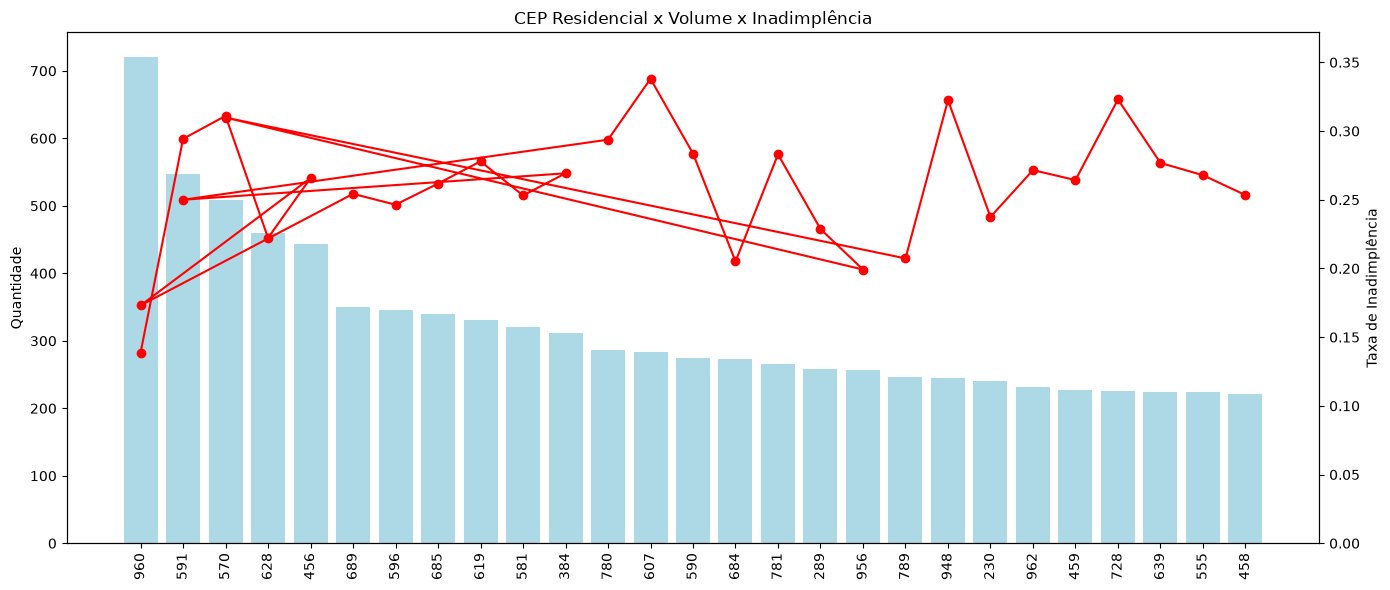

In [38]:

cep_stats = (
    df.groupby('CEP_RESIDENCIAL_3')['ROTULO_ALVO_MAU']
      .agg(['count', 'mean'])
      .sort_values('count', ascending=False)
      .head(30)  # Top 30 CEPs mais frequentes
)

fig, ax1 = plt.subplots(figsize=(14,6))

# Barras = volume
ax1.bar(
    cep_stats.index.astype(str),
    cep_stats['count'],
    color='lightblue'
)

ax1.set_ylabel('Quantidade')
ax1.tick_params(axis='x', rotation=90)

# Linha = inadimplência
ax2 = ax1.twinx()

ax2.plot(
    cep_stats.index.astype(str),
    cep_stats['mean'],
    color='red',
    marker='o'
)

ax2.set_ylabel('Taxa de Inadimplência')
ax2.set_ylim(0, cep_stats['mean'].max()*1.1)

plt.title('CEP Residencial x Volume x Inadimplência')
plt.tight_layout()
plt.show()

**Conclusões baseadas no gráfico**
* O CEP parece ter poder preditivo, a taxa de inadimplência varia aproximadamente entre: 14% (CEP 960) a 35% (CEP 607)
* Isso representa uma diferença de mais de 20 pontos percentuais.
* Os CEPs mais frequentes não possuem a mesma inadimplência
* O CEP 960 chama atenção (maior quantidade de clientes e menor inadimplência observada)
* Um bom começo para avaliar a utilidade da coluna CEP_* para o modelo seria aplicar na coluna o target encoding

In [39]:
# Aplicar o target encoding na coluna CEP_RESIDENCIAL_3

media_global = y_train.mean()

tmp = (
    pd.concat([X_train, y_train], axis=1)
      .groupby('CEP_RESIDENCIAL_3')['ROTULO_ALVO_MAU']
      .agg(['mean', 'count'])
)

m = 100

tmp['target_enc'] = (
    (tmp['count'] * tmp['mean'] + m * media_global)
    / (tmp['count'] + m)
)

map_res = tmp['target_enc']

X_train['CEP_RESIDENCIAL_3_TE'] = (
    X_train['CEP_RESIDENCIAL_3']
    .map(map_res)
    .fillna(media_global)
)

X_test['CEP_RESIDENCIAL_3_TE'] = (
    X_test['CEP_RESIDENCIAL_3']
    .map(map_res)
    .fillna(media_global)
)

In [40]:
# CEP_PROFISSIONAL_3

tmp = (
    pd.concat([X_train, y_train], axis=1)
      .groupby('CEP_PROFISSIONAL_3')['ROTULO_ALVO_MAU']
      .agg(['mean', 'count'])
)

m = 100

tmp['target_enc'] = (
    (tmp['count'] * tmp['mean'] + m * media_global)
    / (tmp['count'] + m)
)

map_prof = tmp['target_enc']

X_train['CEP_PROFISSIONAL_3_TE'] = (
    X_train['CEP_PROFISSIONAL_3']
    .map(map_prof)
    .fillna(media_global)
)

X_test['CEP_PROFISSIONAL_3_TE'] = (
    X_test['CEP_PROFISSIONAL_3']
    .map(map_prof)
    .fillna(media_global)
)


In [41]:
# Remoção das colunas CEP_* original
X_train = X_train.drop(
    columns=[
        'CEP_RESIDENCIAL_3',
        'CEP_PROFISSIONAL_3'
    ]
)

X_test = X_test.drop(
    columns=[
        'CEP_RESIDENCIAL_3',
        'CEP_PROFISSIONAL_3'
    ]
)

In [42]:
# aplicar one hort encoding, Para apenas duas colunas de estado (27 categorias cada), 
# o One-Hot costuma funcionar bem. Porém, como iremos utilizar o XGBoost, uma alternativa mais adequada foi a criação da coluna MESMO_ESTADO
# Colunas para One-Hot Encoding
cols_ohe = ['ESTADO_RESIDENCIAL', 'ESTADO_NASCIMENTO', 'ESTADO_PROFISSIONAL']

# Cria o encoder
ohe = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Ajusta apenas no treino
X_train_ohe = ohe.fit_transform(X_train[cols_ohe])

# Aplica no teste
X_test_ohe = ohe.transform(X_test[cols_ohe])

# Nomes das colunas geradas
colunas_ohe = ohe.get_feature_names_out(cols_ohe)

# Converte para DataFrame
X_train_ohe = pd.DataFrame(
    X_train_ohe,
    columns=colunas_ohe,
    index=X_train.index
)

X_test_ohe = pd.DataFrame(
    X_test_ohe,
    columns=colunas_ohe,
    index=X_test.index
)

#Criar a coluna MESMO_ESTADO
X_train['MESMO_ESTADO'] = (
    X_train['ESTADO_RESIDENCIAL'] == X_train['ESTADO_NASCIMENTO']
).astype(int)

X_test['MESMO_ESTADO'] = (
    X_test['ESTADO_RESIDENCIAL'] == X_test['ESTADO_NASCIMENTO']
).astype(int)

# Remove colunas originais
X_train = X_train.drop(columns=cols_ohe)
X_test = X_test.drop(columns=cols_ohe)

# Adiciona colunas codificadas
X_train = pd.concat([X_train, X_train_ohe], axis=1)
X_test = pd.concat([X_test, X_test_ohe], axis=1)



In [43]:
X_train.head(10)

,DIA_PAGAMENTO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,ESTADO_CIVIL,QUANT_DEPENDENTES,NACIONALIDADE,FLAG_TELEFONE_RESIDENCIAL,TIPO_RESIDENCIA,MESES_RESIDENCIA,FLAG_EMAIL,...,ESTADO_PROFISSIONAL_PR,ESTADO_PROFISSIONAL_RJ,ESTADO_PROFISSIONAL_RN,ESTADO_PROFISSIONAL_RO,ESTADO_PROFISSIONAL_RR,ESTADO_PROFISSIONAL_RS,ESTADO_PROFISSIONAL_SC,ESTADO_PROFISSIONAL_SE,ESTADO_PROFISSIONAL_SP,ESTADO_PROFISSIONAL_TO
38094,25,0,1,1,0,1,Y,1.0,1.0,1,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
40624,10,0,1,2,0,1,Y,1.0,1.0,1,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
49425,10,0,1,2,4,1,Y,1.0,54.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
35734,15,0,1,2,2,1,Y,1.0,15.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
41708,10,0,1,2,3,0,Y,1.0,0.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
31176,10,0,1,1,0,1,Y,1.0,2.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34748,25,0,1,2,1,1,N,1.0,10.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24360,5,0,1,4,0,1,N,1.0,3.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
41276,1,0,1,2,1,1,Y,1.0,3.0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
28248,10,0,1,2,2,1,N,1.0,20.0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [44]:
#O one hot encoding vai criar somente  colunas o que não altera muito a dimensionabilidade do dataframe

# Colunas a codificar
cols_ohe = ['REGIAO_RESIDENCIAL', 'REGIAO_NASCIMENTO']

# Encoder
ohe = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Fit apenas no treino
X_train_encoded = ohe.fit_transform(X_train[cols_ohe])

# Transform no teste
X_test_encoded = ohe.transform(X_test[cols_ohe])

# Nomes das colunas geradas
novas_colunas = ohe.get_feature_names_out(cols_ohe)

# Converter para DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=novas_colunas,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=novas_colunas,
    index=X_test.index
)

# Remover colunas originais
X_train = X_train.drop(columns=cols_ohe)
X_test = X_test.drop(columns=cols_ohe)

# Adicionar colunas codificadas
X_train = pd.concat([X_train, X_train_encoded], axis=1)
X_test = pd.concat([X_test, X_test_encoded], axis=1)

In [45]:
# Converter as colunas FLAG_TELEFONE_RESIDENCIAL e FLAG_TELEFONE_PROFISSIONAL para campos binários
mapeamento = {'Y': 1, 'N': 0}

X_train['FLAG_TELEFONE_RESIDENCIAL'] = (
    X_train['FLAG_TELEFONE_RESIDENCIAL'].map(mapeamento)
)

X_test['FLAG_TELEFONE_RESIDENCIAL'] = (
    X_test['FLAG_TELEFONE_RESIDENCIAL'].map(mapeamento)
)

X_train['FLAG_TELEFONE_PROFISSIONAL'] = (
    X_train['FLAG_TELEFONE_PROFISSIONAL'].map(mapeamento)
)

X_test['FLAG_TELEFONE_PROFISSIONAL'] = (
    X_test['FLAG_TELEFONE_PROFISSIONAL'].map(mapeamento)
)

In [46]:
# Exibindo colunas após todos tratamentos

tipos_colunas = pd.DataFrame({
    'coluna': X_train.columns,
    'tipo': X_train.dtypes.values
}).sort_values('tipo')

print(tipos_colunas.to_string())

                                      coluna     tipo
0                              DIA_PAGAMENTO    int64
49                              MESMO_ESTADO    int64
46    CODIGO_AREA_TELEFONE_RESIDENCIAL_VALID    int64
45   CODIGO_AREA_TELEFONE_PROFISSIONAL_VALID    int64
44                              MESMA_REGIAO    int64
32                                     IDADE    int64
31                                   PRODUTO    int64
30                    FLAG_COMPROVANTE_RENDA    int64
29                                  FLAG_CPF    int64
28                                   FLAG_RG    int64
22                         MESES_NO_TRABALHO    int64
21                FLAG_TELEFONE_PROFISSIONAL    int64
19                              QUANT_CARROS    int64
17          QUANT_CONTAS_BANCARIAS_ESPECIAIS    int64
16                    QUANT_CONTAS_BANCARIAS    int64
27                FLAG_DOCUMENTO_RESIDENCIAL    int64
14                     FLAG_AMERICAN_EXPRESS    int64
15                       FLA

## Pipeline de Classificação usando Random Forest, XGBoost e LightGBM ##

In [47]:
# ==========================================
# RANDOM FOREST
# ==========================================

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

rf_grid = {
'n_estimators': [200, 500],
'max_depth': [5, 10, 20],
'min_samples_split': [2, 10],
'min_samples_leaf': [1, 5],
'max_features': ['sqrt']
}

rf_search = GridSearchCV(
rf,
rf_grid,
cv=5,
scoring='roc_auc',
n_jobs=-1,
verbose=1
)

rf_search.fit(X_train, y_train)

print("Melhores parâmetros RF:")
print(rf_search.best_params_)
print("CV ROC AUC:", rf_search.best_score_)

# Avaliação teste
rf_pred_proba = rf_search.best_estimator_.predict_proba(X_test)[:,1]
rf_auc = roc_auc_score(y_test, rf_pred_proba)

print("\nROC AUC Teste RF:", rf_auc)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


/home/paulosan/Documentos/posmba14dts/Ambiente/MyEnv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/paulosan/Documentos/posmba14dts/Ambiente/MyEnv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/paulosan/Documentos/posmba14dts/Ambiente/MyEnv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.


Melhores parâmetros RF:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 500}
CV ROC AUC: 0.6727202407351054

ROC AUC Teste RF: 0.6181640865870095


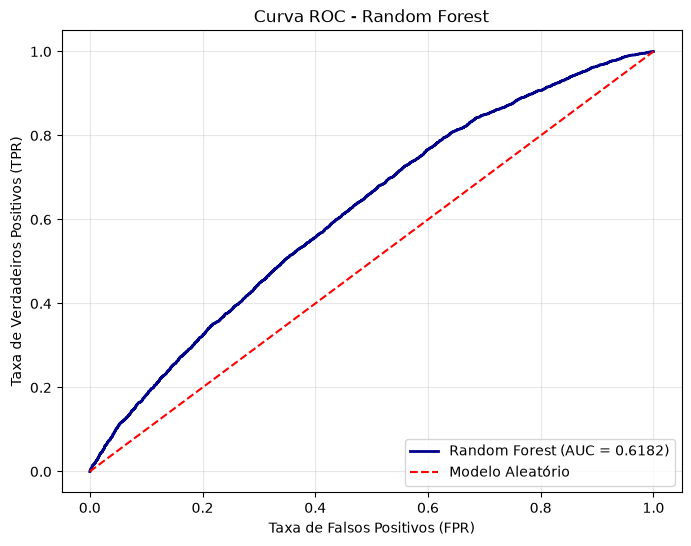

In [48]:


# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, rf_pred_proba)

# Gráfico
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color='darkblue',
    linewidth=2,
    label=f'Random Forest (AUC = {rf_auc:.4f})'
)

# Linha de referência
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='red',
    label='Modelo Aleatório'
)

plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - Random Forest')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()


In [49]:
# ==========================================
# XG Boost
# ==========================================

xgb = XGBClassifier(
objective='binary:logistic',
eval_metric='logloss',
random_state=42
)

xgb_grid = {
'n_estimators': [200, 500],
'max_depth': [3, 5, 7],
'learning_rate': [0.01, 0.05, 0.1],
'subsample': [0.8, 1.0],
'colsample_bytree': [0.8, 1.0]
}

xgb_search = GridSearchCV(
xgb,
xgb_grid,
cv=5,
scoring='roc_auc',
n_jobs=-1,
verbose=1
)

xgb_search.fit(X_train, y_train)

print("Melhores parâmetros XGB:")
print(xgb_search.best_params_)
print("CV ROC AUC:", xgb_search.best_score_)

xgb_pred_proba = xgb_search.best_estimator_.predict_proba(X_test)[:,1]
xgb_auc = roc_auc_score(y_test, xgb_pred_proba)

print("\nROC AUC Teste XGB:", xgb_auc)


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Melhores parâmetros XGB:
{'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}
CV ROC AUC: 0.6824380445474197

ROC AUC Teste XGB: 0.6374497655711313


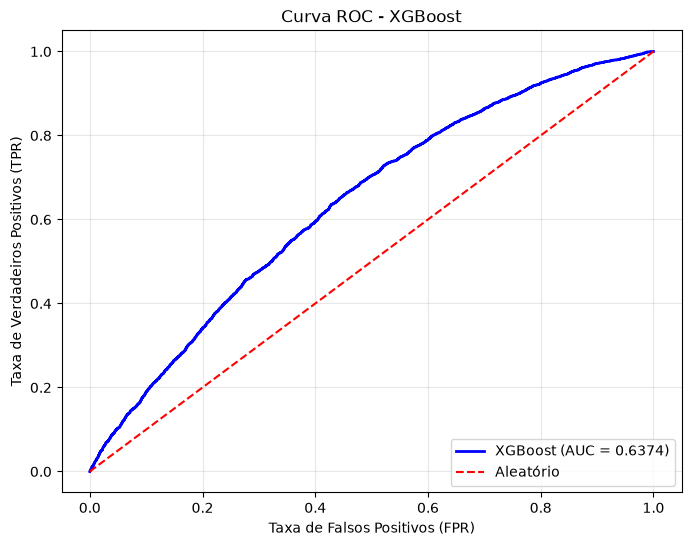

In [51]:
# Grafico curva ROC XG Boost


# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, xgb_pred_proba)



# Gráfico
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'XGBoost (AUC = {xgb_auc:.4f})'
)

# Linha de referência (modelo aleatório)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='red',
    label='Aleatório'
)

plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - XGBoost')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
# ==========================================
# LightGBM
# ==========================================

lgbm = LGBMClassifier(
objective='binary',
random_state=42,
verbose=-1
)

lgbm_grid = {
'n_estimators': [200, 500],
'max_depth': [3, 5, 7, -1],
'learning_rate': [0.01, 0.05, 0.1],
'num_leaves': [31, 50, 100],
'subsample': [0.8, 1.0]
}

lgbm_search = GridSearchCV(
lgbm,
lgbm_grid,
cv=5,
scoring='roc_auc',
n_jobs=-1,
verbose=1
)

lgbm_search.fit(X_train, y_train)

print("Melhores parâmetros LGBM:")
print(lgbm_search.best_params_)
print("CV ROC AUC:", lgbm_search.best_score_)

lgbm_pred_proba = lgbm_search.best_estimator_.predict_proba(X_test)[:,1]
lgbm_auc = roc_auc_score(y_test, lgbm_pred_proba)

print("\nROC AUC Teste LGBM:", lgbm_auc)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


In [ ]:

# Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, lgbm_pred_proba)

# Gráfico
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    color='darkgreen',
    linewidth=2,
    label=f'LightGBM (AUC = {lgbm_auc:.4f})'
)

# Linha de referência
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='red',
    label='Modelo Aleatório'
)

plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)')
plt.title('Curva ROC - LightGBM')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.show()

## Comparação entre os modelos ##

In [ ]:
resultado = {
'RandomForest': rf_auc,
'XGBoost': xgb_auc,
'LightGBM': lgbm_auc
}

for modelo, auc in sorted(resultado.items(),
    key=lambda x: x[1],reverse=True):print(f'{modelo}: {auc:.4f}')